# Prompt Augmentation for Image Generation

This notebook expands a short idea into a detailed image prompt and then generates images. It runs without credentials using deterministic fixtures. Set `RUN_LIVE_OPENAI=1` and `OPENAI_API_KEY` to opt into billable API calls.

In [1]:
import base64, io, os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
LIVE_API = os.getenv('RUN_LIVE_OPENAI', '0') == '1'
OUTPUT_DIR = Path('generated/openai-601'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('mode:', 'live OpenAI API' if LIVE_API else 'deterministic offline fixture')

mode: deterministic offline fixture


## 1. Expand a Short Idea

Live mode uses the current `OpenAI` client and Responses API. The SDK reads `OPENAI_API_KEY` from the environment; no secret file is opened.

In [2]:
def expand_prompt(topic, style):
    if not LIVE_API:
        return f'A luminous {topic}, translucent sugar crystals, sunrise reflections, wide composition, crisp detail, soft haze, {style}.'
    from openai import OpenAI
    response = OpenAI().responses.create(model=os.getenv('OPENAI_TEXT_MODEL', 'gpt-4.1-mini'), input=f'Write one concise image prompt with subject, composition, lighting, and medium. Topic: {topic}. Style: {style}.')
    return response.output_text.strip()
generated_prompt = expand_prompt('sugar castle on a mountain ridge', 'detailed digital illustration')
print(generated_prompt)

A luminous sugar castle on a mountain ridge, translucent sugar crystals, sunrise reflections, wide composition, crisp detail, soft haze, detailed digital illustration.


## 2. Generate, Display, and Save Images

Offline mode creates procedural fixtures. Live mode uses `client.images.generate` and base64 output instead of temporary signed URLs.

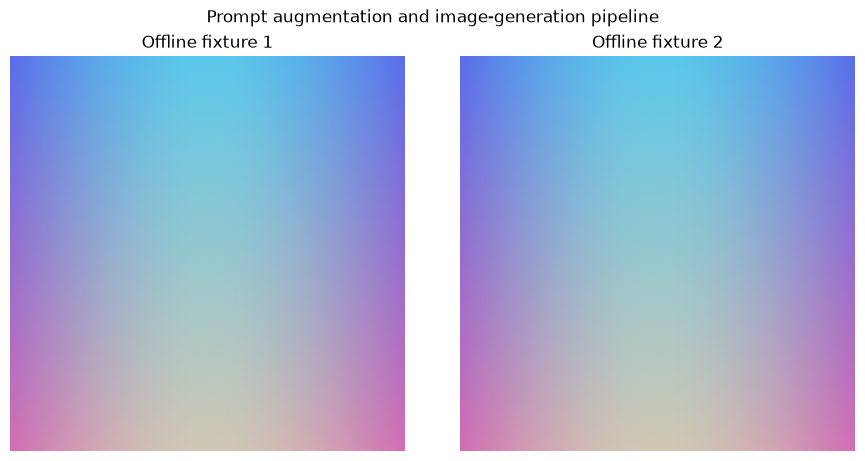

saved: generated\openai-601\prompt-augmentation-results.png


In [3]:
def fixture_image(seed, size=384):
    rng=np.random.default_rng(seed); x=np.linspace(0,1,size); y=np.linspace(0,1,size)[:,None]
    rgb=np.dstack([np.broadcast_to(90+120*y,(size,size)), 110+90*np.sin(np.pi*x)[None,:]*np.ones((size,1)), 180+55*(1-y)+rng.normal(0,3,(size,size))])
    return Image.fromarray(np.clip(rgb,0,255).astype('uint8'))
def generate_images(prompt, count=2):
    if not LIVE_API: return [fixture_image(601+i) for i in range(count)]
    from openai import OpenAI
    response=OpenAI().images.generate(model=os.getenv('OPENAI_IMAGE_MODEL','gpt-image-1'), prompt=prompt, size='1024x1024', n=count, response_format='b64_json')
    return [Image.open(io.BytesIO(base64.b64decode(item.b64_json))).convert('RGB') for item in response.data]
images=generate_images(generated_prompt)
figure, axes=plt.subplots(1,len(images),figsize=(9,4.5),constrained_layout=True)
for index,(axis,image) in enumerate(zip(np.atleast_1d(axes),images)):
    axis.imshow(image); axis.set_title(f"{'Live result' if LIVE_API else 'Offline fixture'} {index+1}"); axis.axis('off')
figure.suptitle('Prompt augmentation and image-generation pipeline')
figure_path=OUTPUT_DIR/'prompt-augmentation-results.png'; figure.savefig(figure_path,dpi=170,bbox_inches='tight'); plt.show()
print('saved:',figure_path)